# 02 — Clean DB1B and T-100 and build the product-level dataset

**Unit of observation.** A *market* is a non-directional airport pair in a quarter (baseline). A *product*
is a ticketing carrier × market × service type, where service type is nonstop (one coupon in the
directional market) or connecting (two coupons). Itineraries with more than one connection are dropped.

**Why non-directional airport pairs (baseline).**
1. Most DB1B trips are round trips, and DB1B Market splits each round trip into two directional market
   records with the itinerary fare prorated between them. Directional fares for the same carrier and route
   are therefore nearly identical, and treating the two directions as separate markets would roughly
   double the number of markets without adding independent price variation (and would understate
   standard errors).
2. The supply-side objects that matter for a merger (airport presence, nonstop service, fleet
   assignment) are symmetric: a carrier that flies A→B flies B→A.
3. The Department of Justice complaints in *U.S. v. JetBlue and Spirit* (2023) and the review of
   Alaska–Hawaiian define relevant markets as origin–destination city pairs without regard to direction.

Airports rather than city markets are used because the airlines compete airport by airport (JFK, LGA and
EWR are differentiated products) and because DB1B fares are reported by airport. Directional
(by trip origin) and city-pair markets are estimated as robustness checks in notebook 06.

**Cleaning steps** (each is logged with record and passenger counts):

| Step | Rule |
|---|---|
| 1 | All DB1B Market records |
| 2 | Both endpoints in the 50 states or DC (drops territories and foreign points) |
| 3 | Drop bulk fares (`BulkFare = 1`), mostly tour-operator and consolidator fares |
| 4 | Drop fares BTS flags as not credible (`DollarCred = 0` in DB1B Ticket); these include frequent-flyer award and zero fares |
| 5 | Drop market fares below \$25 (the standard proxy for award, employee and other non-revenue tickets) |
| 6 | Keep single-ticketing-carrier itineraries (`TkCarrierChange = 0`); interline tickets have no single seller |
| 7 | Keep nonstop and one-stop itineraries (`MktCoupons ≤ 2`) |
| 8 | Drop extreme fares: fare per nonstop mile above the 99th percentile within quarter × distance band |
| 9 | Both endpoint airports located in a Census CBSA (metro or micro area) with population data; drop same-CBSA trips |
| 10 | Aggregate to products; keep products with at least 20 DB1B sample passengers in the quarter (≈200 actual) |
| 11 | Nonstop products must be confirmed by T-100: at least 12 departures in the quarter by the carrier on the segment |
| 12 | Keep markets with at least 100 DB1B sample passengers (≈1,000 actual) after steps 10–11 |
| 13 | Drop markets whose observed traffic exceeds half of the market size (implausibly small potential market) |

In [1]:
%run 00_setup.ipynb

In [2]:
import zipfile, gc
import geopandas as gpd


STATES = {"AL","AK","AZ","AR","CA","CO","CT","DE","DC","FL","GA","HI","ID","IL","IN","IA","KS","KY","LA","ME",
          "MD","MA","MI","MN","MS","MO","MT","NE","NV","NH","NJ","NM","NY","NC","ND","OH","OK","OR","PA","RI",
          "SC","SD","TN","TX","UT","VT","VA","WA","WV","WI","WY"}
MIN_PRODUCT_PAX = 20      # DB1B 10% sample passengers per product-quarter
MIN_NONSTOP_DEPS = 12     # T-100 departures per quarter (both directions) to confirm nonstop service
MIN_MARKET_PAX = 100      # DB1B sample passengers per market-quarter
MAX_INSIDE_SHARE = 0.5
SAMPLE_RATE = 10          # DB1B is a 10% ticket sample

def read_zip_csv(path, usecols, dtype=None):
    with zipfile.ZipFile(path) as z:
        name = max((i for i in z.infolist() if i.filename.lower().endswith(".csv")), key=lambda i: i.file_size).filename
        with z.open(name) as f:
            d = pd.read_csv(f, usecols=usecols, engine="pyarrow")
    for c, t in (dtype or {}).items():
        d[c] = d[c].astype(t)
    return d

## Airports → CBSA → population

In [3]:
coord = read_zip_csv(RAW / "airports" / "master_coordinate.zip", None)
coord.columns = [c.upper() for c in coord.columns]
coord = coord[(coord.AIRPORT_IS_LATEST == 1) & (coord.AIRPORT_COUNTRY_CODE_ISO == "US")
              & coord.LATITUDE.notna()].drop_duplicates("AIRPORT")
apts = gpd.GeoDataFrame(coord[["AIRPORT", "DISPLAY_AIRPORT_NAME", "AIRPORT_STATE_CODE", "CITY_MARKET_ID"]],
                        geometry=gpd.points_from_xy(coord.LONGITUDE, coord.LATITUDE), crs="EPSG:4269")
cbsa_shp = gpd.read_file(f"zip://{RAW / 'census' / 'cb_2024_us_cbsa_500k.zip'}")[["CBSAFP", "NAME", "LSAD", "geometry"]]
inside = gpd.sjoin(apts, cbsa_shp.to_crs(apts.crs), how="left", predicate="within").drop(columns="index_right")
# Airports just outside a CBSA boundary are assigned to the nearest CBSA within 40 km.
miss = inside.CBSAFP.isna()
near = gpd.sjoin_nearest(apts[miss.values].to_crs("EPSG:5070"), cbsa_shp.to_crs("EPSG:5070"),
                         how="left", max_distance=40_000).drop(columns="index_right")
inside.loc[miss, ["CBSAFP", "NAME", "LSAD"]] = near[["CBSAFP", "NAME", "LSAD"]].values
airport_cbsa = pd.DataFrame(inside.drop(columns="geometry")).rename(columns={"NAME": "CBSA_NAME"})
airport_cbsa = airport_cbsa.drop_duplicates("AIRPORT")
print("airports:", len(airport_cbsa), "| in a CBSA:", airport_cbsa.CBSAFP.notna().sum(),
      "| by nearest-within-40km:", int(miss.sum() - airport_cbsa.loc[miss.values, 'CBSAFP'].isna().sum()))

pop = pd.read_csv(RAW / "census" / "cbsa-est2025-alldata.csv", encoding="latin-1", dtype={"CBSA": str})
pop = pop[pop.LSAD.isin(["Metropolitan Statistical Area", "Micropolitan Statistical Area"])]
pop_long = (pop.melt(id_vars=["CBSA"], value_vars=[f"POPESTIMATE{y}" for y in range(2022, 2026)],
                     var_name="var", value_name="pop")
              .assign(Year=lambda d: d["var"].str[-4:].astype(int)).drop(columns="var"))
pop_lookup = pop_long.set_index(["CBSA", "Year"])["pop"]
airport_cbsa = airport_cbsa[airport_cbsa.CBSAFP.isin(pop.CBSA)]
apt2cbsa = airport_cbsa.set_index("AIRPORT")["CBSAFP"]
airport_cbsa.to_parquet(CLEAN / "airport_cbsa.parquet", index=False)
print("airports with CBSA population:", len(apt2cbsa))

airports: 2967 | in a CBSA: 2295 | by nearest-within-40km: 385
airports with CBSA population: 2280


## Price deflator (CPI-U, 2025Q2 dollars)

In [4]:
cpi = pd.read_csv(RAW / "cpi" / "CPIAUCSL.csv")
cpi.columns = ["date", "cpi"]
cpi["date"] = pd.to_datetime(cpi.date)
cpi = cpi.assign(Year=cpi.date.dt.year, Quarter=cpi.date.dt.quarter).groupby(["Year", "Quarter"]).cpi.mean()
deflator = (cpi.loc[LAST_Q] / cpi).rename("deflator")
deflator.loc[[q for q in QUARTERS]].round(4).to_frame().T

Year        2022                            2023                          \
Quarter        1       2       3       4       1       2       3       4   
deflator  1.1259  1.1001  1.0857  1.0745  1.0649  1.0573  1.0484  1.0409   

Year        2024                            2025       
Quarter        1       2       3       4       1    2  
deflator  1.0315  1.0246  1.0212  1.0133  1.0041  1.0

## T-100 segments: scheduled passenger service by operating carrier

In [5]:
t100 = []
for y in sorted({y for y, _ in QUARTERS}):
    d = read_zip_csv(RAW / "t100" / f"T100_domestic_segment_{y}.zip", None)
    d.columns = [c.upper() for c in d.columns]
    t100.append(d)
t100 = pd.concat(t100, ignore_index=True)
n0 = len(t100)
t100 = t100[(t100.CLASS == "F") & (t100.AIRCRAFT_CONFIG == 1) & (t100.DEPARTURES_PERFORMED > 0)]
QSET = set(QUARTERS)
t100 = t100[[(y, q) in QSET for y, q in zip(t100.YEAR, t100.QUARTER)]]
print(f"T-100 rows {n0:,} -> {len(t100):,} scheduled passenger (class F, passenger configuration)")
seg = (t100.groupby(["UNIQUE_CARRIER", "ORIGIN", "DEST", "YEAR", "QUARTER"], as_index=False)
           [["DEPARTURES_SCHEDULED", "DEPARTURES_PERFORMED", "SEATS", "PASSENGERS"]].sum()
           .rename(columns={"UNIQUE_CARRIER": "op", "YEAR": "Year", "QUARTER": "Quarter"}))
seg.to_parquet(CLEAN / "t100_segments_quarter.parquet", index=False)
seg.head()

T-100 rows 1,726,338 -> 1,115,887 scheduled passenger (class F, passenger configuration)


,op,ORIGIN,DEST,Year,Quarter,DEPARTURES_SCHEDULED,DEPARTURES_PERFORMED,SEATS,PASSENGERS
0,1BQ,JFK,JFK,2022,1,1.0,1.0,255.0,0.0
1,1BQ,PHL,JFK,2022,1,1.0,1.0,255.0,80.0
2,1QQ,STT,STX,2022,1,190.0,224.0,2016.0,1049.0
3,1QQ,STT,STX,2022,2,384.0,384.0,3456.0,2475.0
4,1QQ,STT,STX,2022,3,351.0,351.0,3159.0,1958.0


## DB1B: clean each quarter

Fares are prorated market fares (`MktFare`), i.e. one-way equivalents, deflated to 2025Q2 dollars.
While reading the raw nonstop records we also record which ticketing (marketing) carrier sells the seats of
each operating carrier on each segment. This lets us attribute T-100 departures of regional carriers
(e.g. SkyWest, Republic) to the brands that sell them.

In [6]:
MKT_COLS = ["ItinID", "MktCoupons", "Year", "Quarter", "Origin", "OriginCityMarketID", "OriginState",
            "Dest", "DestCityMarketID", "DestState", "TkCarrierChange", "TkCarrier", "OpCarrier",
            "BulkFare", "Passengers", "MktFare", "MktMilesFlown", "NonStopMiles"]
MKT_DTYPE = {"Origin": "category", "Dest": "category", "OriginState": "category", "DestState": "category",
             "TkCarrier": "category", "OpCarrier": "category"}
TKT_COLS = ["ItinID", "Origin", "DollarCred"]

log_rows, opmap_parts = [], []

def log(step, d, y, q, desc):
    log_rows.append({"Year": y, "Quarter": q, "step": step, "description": desc,
                     "records": len(d), "passengers": float(d.Passengers.sum())})

for (y, q) in QUARTERS:
    out = INTERIM / f"db1b_clean_{y}Q{q}.parquet"
    f_log, f_map = INTERIM / f"log_{y}Q{q}.csv", INTERIM / f"opmap_{y}Q{q}.parquet"
    if out.exists() and f_log.exists() and f_map.exists():      # cached from an earlier run
        log_rows += pd.read_csv(f_log).to_dict("records")
        opmap_parts.append(pd.read_parquet(f_map))
        continue
    n_log = len(log_rows)
    m = read_zip_csv(RAW / "db1b" / f"Origin_and_Destination_Survey_DB1BMarket_{y}_{q}.zip", MKT_COLS, MKT_DTYPE)
    log(1, m, y, q, "Raw DB1B Market records")
    # operating -> ticketing carrier passenger split on nonstop segments (all fares)
    ns = m[(m.MktCoupons == 1) & (m.OpCarrier.astype(str) != "99")]
    opmap_parts.append(ns.groupby(["OpCarrier", "TkCarrier", "Origin", "Dest"], observed=True)
                         .Passengers.sum().reset_index().assign(Year=y, Quarter=q))
    m = m[m.OriginState.isin(STATES) & m.DestState.isin(STATES)]
    log(2, m, y, q, "Both endpoints in 50 states + DC")
    m = m[m.BulkFare != 1]
    log(3, m, y, q, "Drop bulk fares")
    t = read_zip_csv(RAW / "db1b" / f"Origin_and_Destination_Survey_DB1BTicket_{y}_{q}.zip", TKT_COLS,
                     {"Origin": "category"}).rename(columns={"Origin": "TripOrigin"})
    m = m.merge(t, on="ItinID", how="left")
    del t; gc.collect()
    m = m[m.DollarCred != 0]
    log(4, m, y, q, "Drop fares flagged not credible (DollarCred = 0)")
    m = m[m.MktFare >= 25]
    log(5, m, y, q, "Drop fares below $25")
    m = m[(m.TkCarrierChange == 0) & (m.TkCarrier.astype(str) != "99")]
    log(6, m, y, q, "Single ticketing carrier")
    m = m[m.MktCoupons <= 2]
    log(7, m, y, q, "Nonstop or one-stop")
    fpm = m.MktFare / m.NonStopMiles.clip(lower=1)
    band = pd.cut(m.NonStopMiles, [0, 250, 500, 750, 1000, 1500, 2000, 2500, 3000, 10000])
    cut = fpm.groupby(band, observed=True).transform(lambda s: s.quantile(0.99))
    m = m[fpm <= cut]
    log(8, m, y, q, "Drop fare per mile above 99th pct (quarter x distance band)")
    o_cbsa = m.Origin.astype(str).map(apt2cbsa)
    d_cbsa = m.Dest.astype(str).map(apt2cbsa)
    m = m[o_cbsa.notna() & d_cbsa.notna() & (o_cbsa != d_cbsa)]
    log(9, m, y, q, "Both endpoints in a CBSA with population data")
    keep = ["Year", "Quarter", "Origin", "Dest", "TripOrigin", "OriginCityMarketID", "DestCityMarketID",
            "TkCarrier", "MktCoupons", "Passengers", "MktFare", "MktMilesFlown", "NonStopMiles"]
    m = m[keep].copy()
    for c in ["Origin", "Dest", "TripOrigin", "TkCarrier"]:
        m[c] = m[c].astype(str)
    m["MktFare"] = m.MktFare * deflator.loc[(y, q)]
    m.to_parquet(out, index=False)
    pd.DataFrame(log_rows[n_log:]).to_csv(f_log, index=False)
    opmap_parts[-1].astype({c: str for c in ["OpCarrier", "TkCarrier", "Origin", "Dest"]}).to_parquet(f_map, index=False)
    print(f"{y}Q{q}: {log_rows[n_log]['records']:,} raw -> {len(m):,} clean records")
    del m; gc.collect()

2022Q1: 6,078,763 raw -> 5,298,747 clean records


2022Q2: 7,478,826 raw -> 6,580,018 clean records


2022Q3: 7,045,674 raw -> 6,189,840 clean records


2022Q4: 7,254,531 raw -> 6,366,923 clean records


2023Q1: 6,714,113 raw -> 5,836,299 clean records


...

2024Q2: 8,533,978 raw -> 7,526,774 clean records


2024Q3: 8,297,869 raw -> 7,309,100 clean records


2024Q4: 8,525,077 raw -> 7,483,825 clean records


2025Q1: 7,297,028 raw -> 6,314,584 clean records


2025Q2: 8,450,420 raw -> 7,371,158 clean records


## Attribute T-100 departures to marketing carriers; airport presence

For each operating carrier, segment and quarter, departures are split across ticketing carriers in
proportion to the DB1B nonstop passengers each one sold on that segment. Where a segment has no DB1B
record, the split for that operating carrier at the origin airport (then nationally) is used.

In [7]:
opmap = pd.concat(opmap_parts, ignore_index=True)
for c in ["OpCarrier", "TkCarrier", "Origin", "Dest"]:
    opmap[c] = opmap[c].astype(str)
opmap = opmap[opmap.TkCarrier != "99"]
opmap["a"] = np.minimum(opmap.Origin, opmap.Dest)
opmap["b"] = np.maximum(opmap.Origin, opmap.Dest)

def shares(df, keys):
    g = df.groupby(keys + ["TkCarrier"], as_index=False).Passengers.sum()
    g["w"] = g.Passengers / g.groupby(keys).Passengers.transform("sum")
    return g.drop(columns="Passengers")

sh_seg = shares(opmap, ["OpCarrier", "a", "b", "Year", "Quarter"])
sh_apt = shares(opmap.assign(apt=opmap.Origin), ["OpCarrier", "apt", "Year", "Quarter"])
sh_nat = shares(opmap, ["OpCarrier", "Year", "Quarter"])

s = seg.rename(columns={"op": "OpCarrier"}).copy()
s["a"] = np.minimum(s.ORIGIN, s.DEST)
s["b"] = np.maximum(s.ORIGIN, s.DEST)
s["sid"] = np.arange(len(s))
alloc1 = s.merge(sh_seg, on=["OpCarrier", "a", "b", "Year", "Quarter"])
rest = s[~s.sid.isin(alloc1.sid)]
alloc2 = rest.merge(sh_apt.rename(columns={"apt": "ORIGIN"}), on=["OpCarrier", "ORIGIN", "Year", "Quarter"])
rest = rest[~rest.sid.isin(alloc2.sid)]
alloc3 = rest.merge(sh_nat, on=["OpCarrier", "Year", "Quarter"])
rest = rest[~rest.sid.isin(alloc3.sid)].assign(TkCarrier=lambda d: d.OpCarrier, w=1.0)
alloc = pd.concat([alloc1, alloc2, alloc3, rest], ignore_index=True)
alloc["deps"] = alloc.DEPARTURES_PERFORMED * alloc.w
print("share of T-100 departures allocated by segment / airport / national / self:",
      [round(x.DEPARTURES_PERFORMED.mul(x.w).sum() / s.DEPARTURES_PERFORMED.sum(), 3)
       for x in (alloc1, alloc2, alloc3, rest)])

# airport presence: carrier's share of departures from the airport
dep_c = alloc.groupby(["TkCarrier", "ORIGIN", "Year", "Quarter"], as_index=False).deps.sum()
dep_c["presence"] = dep_c.deps / dep_c.groupby(["ORIGIN", "Year", "Quarter"]).deps.transform("sum")
presence = dep_c.rename(columns={"TkCarrier": "carrier", "ORIGIN": "airport"})
presence.to_parquet(CLEAN / "airport_presence.parquet", index=False)
# nonstop departures by marketing carrier on the non-directional segment
seg_mkt = alloc.groupby(["TkCarrier", "a", "b", "Year", "Quarter"], as_index=False).deps.sum()
presence.sort_values("presence", ascending=False).query("Year == 2025 and Quarter == 2").head(10)

share of T-100 departures allocated by segment / airport / national / self: [np.float64(0.947), np.float64(0.008), np.float64(0.009), np.float64(0.036)]


,carrier,airport,Year,Quarter,deps,presence
13278,DL,INL,2025,2,156.0,1.0
97,3AQ,KQA,2025,2,206.0,1.0
13250,DL,IMT,2025,2,182.0,1.0
32096,XP,LAL,2025,2,161.0,1.0
32075,XP,ILG,2025,2,297.0,1.0
31796,WST,RNT,2025,2,37.0,1.0
13559,DL,LWS,2025,2,182.0,1.0
31737,WRD,EXI,2025,2,31.0,1.0
13086,DL,HIB,2025,2,159.0,1.0
12709,DL,ESC,2025,2,155.0,1.0


## Aggregate to products

`build_products` is written for all three market definitions used in the project.

In [8]:
def market_keys(d, definition):
    if definition == "airport_nondir":
        return np.minimum(d.Origin, d.Dest), np.maximum(d.Origin, d.Dest)
    if definition == "airport_dir":
        # direction of the trip: the market starts at the trip origin when that is one of the endpoints
        start_at_dest = (d.TripOrigin == d.Dest) & (d.TripOrigin != d.Origin)
        return np.where(start_at_dest, d.Dest, d.Origin), np.where(start_at_dest, d.Origin, d.Dest)
    if definition == "city_nondir":
        o, de = d.OriginCityMarketID.astype(str), d.DestCityMarketID.astype(str)
        return np.minimum(o, de), np.maximum(o, de)
    raise ValueError(definition)

def build_products(definition, verbose=True):
    parts = []
    for (y, q) in QUARTERS:
        d = pd.read_parquet(INTERIM / f"db1b_clean_{y}Q{q}.parquet")
        d["a"], d["b"] = market_keys(d, definition)
        d["nonstop"] = (d.MktCoupons == 1).astype(int)
        d["fare_x"] = d.MktFare * d.Passengers
        d["miles_x"] = d.MktMilesFlown * d.Passengers
        d["nsm_x"] = d.NonStopMiles * d.Passengers
        g = d.groupby(["Year", "Quarter", "a", "b", "TkCarrier", "nonstop"], as_index=False).agg(
            pax=("Passengers", "sum"), fare_x=("fare_x", "sum"), miles_x=("miles_x", "sum"),
            nsm_x=("nsm_x", "sum"), records=("Passengers", "size"))
        parts.append(g)
    p = pd.concat(parts, ignore_index=True)
    p["fare"] = p.fare_x / p.pax
    p["miles_flown"] = p.miles_x / p.pax
    p["nonstop_miles"] = p.nsm_x / p.pax
    p = p.drop(columns=["fare_x", "miles_x", "nsm_x"])
    return p

def finish_products(p, definition, logrows):
    def L(step, d, desc):
        logrows.append({"step": step, "description": desc, "records": int(d.records.sum()),
                        "passengers": float(d.pax.sum()), "products": len(d),
                        "markets": d.groupby(["Year", "Quarter", "a", "b"]).ngroups})
    L(10, p, "Aggregated to carrier x market x service type")
    p = p[p.pax >= MIN_PRODUCT_PAX].copy()
    L(10.5, p, f"Products with >= {MIN_PRODUCT_PAX} sample passengers")
    # T-100 confirmation of nonstop service
    if definition == "city_nondir":
        segm = seg_mkt.assign(ca=seg_mkt.a.map(apt_city), cb=seg_mkt.b.map(apt_city)).dropna(subset=["ca", "cb"])
        segm = segm.assign(a=np.minimum(segm.ca, segm.cb), b=np.maximum(segm.ca, segm.cb))
        segm = segm.groupby(["TkCarrier", "a", "b", "Year", "Quarter"], as_index=False).deps.sum()
        p = p.merge(segm.rename(columns={"deps": "ns_deps"}), on=["TkCarrier", "a", "b", "Year", "Quarter"], how="left")
    else:
        sa, sb = np.minimum(p.a, p.b), np.maximum(p.a, p.b)
        p = p.assign(sa=sa, sb=sb).merge(
            seg_mkt.rename(columns={"a": "sa", "b": "sb", "deps": "ns_deps"}),
            on=["TkCarrier", "sa", "sb", "Year", "Quarter"], how="left").drop(columns=["sa", "sb"])
    p["ns_deps"] = p.ns_deps.fillna(0)
    p = p[(p.nonstop == 0) | (p.ns_deps >= MIN_NONSTOP_DEPS)]
    L(11, p, f"Nonstop products confirmed by T-100 (>= {MIN_NONSTOP_DEPS} departures)")
    mk = p.groupby(["Year", "Quarter", "a", "b"]).pax.transform("sum")
    p = p[mk >= MIN_MARKET_PAX].copy()
    L(12, p, f"Markets with >= {MIN_MARKET_PAX} sample passengers")
    # market size: geometric mean of endpoint CBSA populations
    if definition == "city_nondir":
        ca, cb = p.a.map(city_cbsa), p.b.map(city_cbsa)
    else:
        ca, cb = p.a.map(apt2cbsa), p.b.map(apt2cbsa)
    pa = pd.Series(list(zip(ca, p.Year))).map(pop_lookup).values
    pb = pd.Series(list(zip(cb, p.Year))).map(pop_lookup).values
    p["cbsa_a"], p["cbsa_b"] = ca.values, cb.values
    p["pop_a"], p["pop_b"] = pa, pb
    p["market_size"] = np.sqrt(pa * pb)
    p["passengers"] = p.pax * SAMPLE_RATE
    p["shares"] = p.passengers / p.market_size
    inside = p.groupby(["Year", "Quarter", "a", "b"]).shares.transform("sum")
    p = p[(inside < MAX_INSIDE_SHARE) & np.isfinite(inside)].copy()
    L(13, p, f"Drop markets with inside share >= {MAX_INSIDE_SHARE}")
    # characteristics
    pres = presence.set_index(["carrier", "airport", "Year", "Quarter"]).presence
    if definition == "city_nondir":
        ea, eb = p.a.map(city_rep), p.b.map(city_rep)
    else:
        ea, eb = p.a, p.b
    pr_a = pd.Series(list(zip(p.TkCarrier, ea, p.Year, p.Quarter))).map(pres).fillna(0).values
    pr_b = pd.Series(list(zip(p.TkCarrier, eb, p.Year, p.Quarter))).map(pres).fillna(0).values
    p["presence_a"], p["presence_b"] = pr_a, pr_b
    p["hub_presence"] = (pr_a + pr_b) / 2
    p["hub_presence_origin"] = pr_a
    p["carrier"] = p.TkCarrier
    p["carrier_fe"] = np.where(p.carrier.isin(MAJOR_CARRIERS), p.carrier, "OTH")
    p["quarter"] = [qlabel(y, q) for y, q in zip(p.Year, p.Quarter)]
    p["t"] = qindex(p.Year, p.Quarter)
    p["route"] = p.a + "-" + p.b
    p["market_ids"] = p.route + "|" + p.quarter
    p["prices"] = p.fare / 100                    # $100s of 2025Q2 dollars
    p["distance"] = p.miles_flown / 1000          # thousands of miles flown
    p["route_distance"] = p.groupby("route").nonstop_miles.transform("median") / 1000
    p["n_carriers"] = p.groupby("market_ids").carrier.transform("nunique")
    p["n_products"] = p.groupby("market_ids").carrier.transform("size")
    p = p.sort_values(["t", "route", "carrier", "nonstop"]).reset_index(drop=True)
    return p

In [9]:
# city-market helpers (used only for the city-pair robustness market definition)
last = pd.read_parquet(INTERIM / f"db1b_clean_{LAST_Q[0]}Q{LAST_Q[1]}.parquet")
last = last.assign(Origin=last.Origin.astype(str), OriginCityMarketID=last.OriginCityMarketID.astype(str))
busiest = last.groupby(["OriginCityMarketID", "Origin"]).Passengers.sum().reset_index() \
              .sort_values("Passengers").drop_duplicates("OriginCityMarketID", keep="last")
city_rep = busiest.set_index("OriginCityMarketID").Origin            # city market -> busiest airport
city_cbsa = city_rep.map(apt2cbsa)
apt_city = pd.concat([pd.read_parquet(INTERIM / f"db1b_clean_{y}Q{q}.parquet", columns=["Origin", "OriginCityMarketID"])
                      .drop_duplicates() for (y, q) in QUARTERS]).drop_duplicates("Origin").astype(str) \
             .set_index("Origin").OriginCityMarketID
del last

In [10]:
datasets = {}
product_logs = {}
for definition in ["airport_nondir", "airport_dir", "city_nondir"]:
    rows = []
    p = finish_products(build_products(definition), definition, rows)
    p.to_parquet(CLEAN / f"products_{definition}.parquet", index=False)
    datasets[definition] = p
    product_logs[definition] = pd.DataFrame(rows)
    print(definition, f"{len(p):,} products, {p.market_ids.nunique():,} markets, {p.route.nunique():,} routes")

airport_nondir 334,945 products, 100,269 markets, 9,211 routes


airport_dir 463,254 products, 138,964 markets, 13,068 routes


city_nondir 287,276 products, 80,066 markets, 7,363 routes


## Cleaning log (record-level steps 1–9 summed over quarters; product-level steps 10–13, baseline)

In [11]:
lg = pd.DataFrame(log_rows)
lg.to_csv(RES / "cleaning_log_by_quarter.csv", index=False)
rec = lg.groupby(["step", "description"], as_index=False)[["records", "passengers"]].sum()
prod = product_logs["airport_nondir"].groupby(["step", "description"], as_index=False).last()
tab = pd.concat([rec, prod], ignore_index=True)
tab["records dropped"] = (-tab.records.diff()).where(tab.step <= 9)
tab["share of raw passengers"] = tab.passengers / tab.passengers.iloc[0]
tab.to_csv(RES / "cleaning_log.csv", index=False)
show = tab[["step", "description", "records", "passengers", "products", "markets", "share of raw passengers"]].copy()
show["step"] = show.step.map(lambda s: f"{s:g}" if s != 10.5 else "10b")
for c in ["records", "passengers", "products", "markets"]:
    show[c] = show[c].map(lambda v: "" if pd.isna(v) else f"{v:,.0f}")
show["share of raw passengers"] = show["share of raw passengers"].map(lambda v: f"{v:.3f}")
save_table(show.set_index("step"), "cleaning_log", float_format="%.3f",
           note="DB1B Market 10\\% sample, 2022Q1--2025Q2. Records and passengers are DB1B sample counts. "
                "Steps 10--13 refer to the baseline non-directional airport-pair dataset.")
for k, v in product_logs.items():
    v.to_csv(RES / f"cleaning_log_products_{k}.csv", index=False)
show

saved /home/user/BLP-/output/tables/cleaning_log.tex


,step,description,records,passengers,products,markets,share of raw passengers
0,1,Raw DB1B Market records,"105,807,120","206,644,154",,,1.000
1,2,Both endpoints in 50 states + DC,"103,687,758","202,158,106",,,0.978
2,3,Drop bulk fares,"103,678,179","202,146,231",,,0.978
3,4,Drop fares flagged not credible (DollarCred = 0),"103,189,944","201,607,442",,,0.976
4,5,Drop fares below $25,"97,956,992","181,583,102",,,0.879
5,6,Single ticketing carrier,"96,405,850","179,932,964",,,0.871
6,7,Nonstop or one-stop,"94,829,115","178,324,800",,,0.863
7,8,Drop fare per mile above 99th pct (quarter x d...,"93,880,832","177,257,561",,,0.858
8,9,Both endpoints in a CBSA with population data,"92,647,009","174,681,984",,,0.845
9,10,Aggregated to carrier x market x service type,"92,647,009","174,681,984","847,717","368,298",0.845


## Descriptive statistics (baseline dataset)

In [12]:
p = datasets["airport_nondir"]
desc = pd.DataFrame({
    "Fare (2025Q2 $)": p.fare, "Nonstop": p.nonstop, "Miles flown (000)": p.distance,
    "Hub presence": p.hub_presence, "Passengers (quarter)": p.passengers, "Share": p.shares,
    "Carriers in market": p.n_carriers, "Products in market": p.n_products,
}).describe(percentiles=[0.1, 0.5, 0.9]).T[["mean", "std", "10%", "50%", "90%"]]
save_table(desc, "descriptives", float_format="%.3f",
           note=f"{len(p):,} products in {p.market_ids.nunique():,} markets ({p.route.nunique():,} airport pairs), 2022Q1--2025Q2.")
by_carrier = p.groupby("carrier_fe").agg(products=("shares", "size"), passengers_m=("passengers", lambda s: s.sum() / 1e6),
                                          mean_fare=("fare", "mean"), nonstop_share=("nonstop", "mean"),
                                          mean_presence=("hub_presence", "mean")).sort_values("passengers_m", ascending=False)
by_carrier.index = by_carrier.index.map(lambda c: CARRIER_NAMES.get(c, c))
save_table(by_carrier, "descriptives_by_carrier", float_format="%.2f",
           note="Passengers in millions (DB1B sample $\\times$ 10), all quarters.")
desc

saved /home/user/BLP-/output/tables/descriptives.tex
saved /home/user/BLP-/output/tables/descriptives_by_carrier.tex


,mean,std,10%,50%,90%
Fare (2025Q2 $),295.686185,105.679526,164.123657,290.372954,423.045270
Nonstop,0.187792,0.390547,0.000000,0.000000,1.000000
Miles flown (000),1.466559,0.822089,0.612000,1.268381,2.499840
Hub presence,0.245897,0.154592,0.070144,0.213451,0.474102
Passengers (quarter),4957.085671,13344.868087,320.000000,1100.000000,11060.000000
Share,0.002129,0.005629,0.000162,0.000732,0.005079
Carriers in market,3.769464,1.513876,2.000000,4.000000,6.000000
Products in market,4.392909,2.207347,2.000000,4.000000,8.000000


saved /home/user/BLP-/output/figures/fare_distribution.pdf


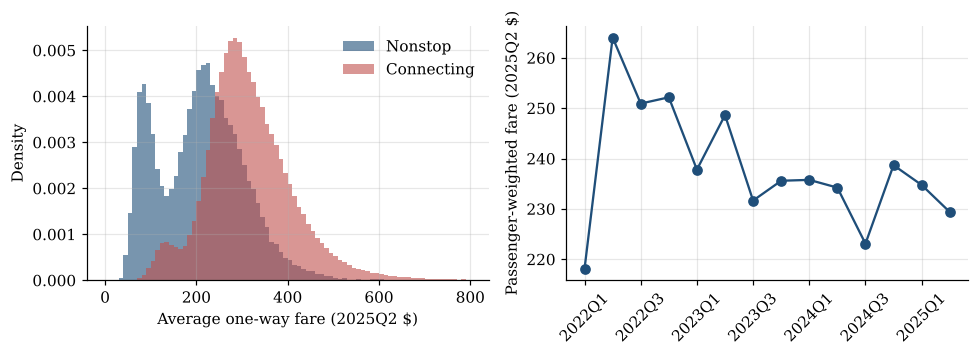

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ns, lab in [(1, "Nonstop"), (0, "Connecting")]:
    axes[0].hist(p.loc[p.nonstop == ns, "fare"], bins=80, range=(0, 800), alpha=0.6, density=True, label=lab)
axes[0].set_xlabel("Average one-way fare (2025Q2 $)"); axes[0].set_ylabel("Density"); axes[0].legend()
ts = p.groupby(["t", "quarter"]).apply(lambda d: np.average(d.fare, weights=d.passengers)).reset_index(name="fare")
axes[1].plot(ts.t, ts.fare, marker="o")
axes[1].set_xticks(ts.t[::2]); axes[1].set_xticklabels(ts.quarter[::2], rotation=45)
axes[1].set_ylabel("Passenger-weighted fare (2025Q2 $)")
fig.tight_layout(); savefig(fig, "fare_distribution")